# 5_1 노트북: 주택 가격 예측과 회귀

이 복사본에는 각 코드 셀 앞에 초보자용 한국어 설명을 추가했습니다. 위에서 아래 순서대로 실행하면 데이터 준비, 선형 회귀, 다항 회귀, Ridge/Lasso/ElasticNet 규제 모델을 살펴볼 수 있습니다.

이 파일은 UTF-8 인코딩으로 저장했습니다. 원본의 표/그래프 출력은 유지했습니다. 일부 출력은 원본 실행 당시의 결과이며, 현재 환경이나 라이브러리 버전에서 다시 실행하면 값이 달라질 수 있습니다.

In [2]:
# 1. 분석에 필요한 도구를 불러옵니다.
# import는 다른 사람이 만든 기능 묶음(라이브러리)을 현재 노트북에서 쓸 수 있게 합니다.
# numpy는 숫자 배열과 수학 계산, pandas는 표 형태 데이터 처리, matplotlib/seaborn은 그래프에 씁니다.
# scipy.stats는 통계 기능, fetch_california_housing은 예제 주택 데이터를 가져오는 함수입니다.
# as np처럼 별칭을 붙이면 매번 긴 라이브러리 이름을 쓰지 않아도 됩니다.
# warnings.filterwarnings('ignore')는 경고 메시지를 숨깁니다. 오류를 고치는 기능은 아니므로,
# 학습할 때는 경고도 살펴보는 편이 좋습니다.

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.datasets import fetch_california_housing

import warnings
warnings.filterwarnings("ignore")




In [3]:
# 2. 캘리포니아 주택 예제 데이터를 불러와 pandas 표(DataFrame)로 만듭니다.
# housing에는 입력 특성(data), 특성 이름(feature_names), 정답(target) 등이 들어 있습니다.
# DataFrame은 행과 열로 정리된 표입니다. 열 이름을 데이터에 맞춰 지정합니다.
# head()는 표의 맨 앞 다섯 행을 보여 주어 데이터 모양을 빠르게 확인합니다.

housing = fetch_california_housing()

df = pd.DataFrame(housing.data, columns= housing.feature_names)
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [4]:
# 3. 예측하려는 정답값을 PRICE라는 새 열로 표에 추가합니다.
# housing.target은 각 지역의 주택 가격 중앙값이며, 모델이 맞혀야 하는 값입니다.
# shape는 (행 개수, 열 개수)를 반환합니다. head()로 추가된 열까지 확인합니다.

df["PRICE"] = housing.target
print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,PRICE
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


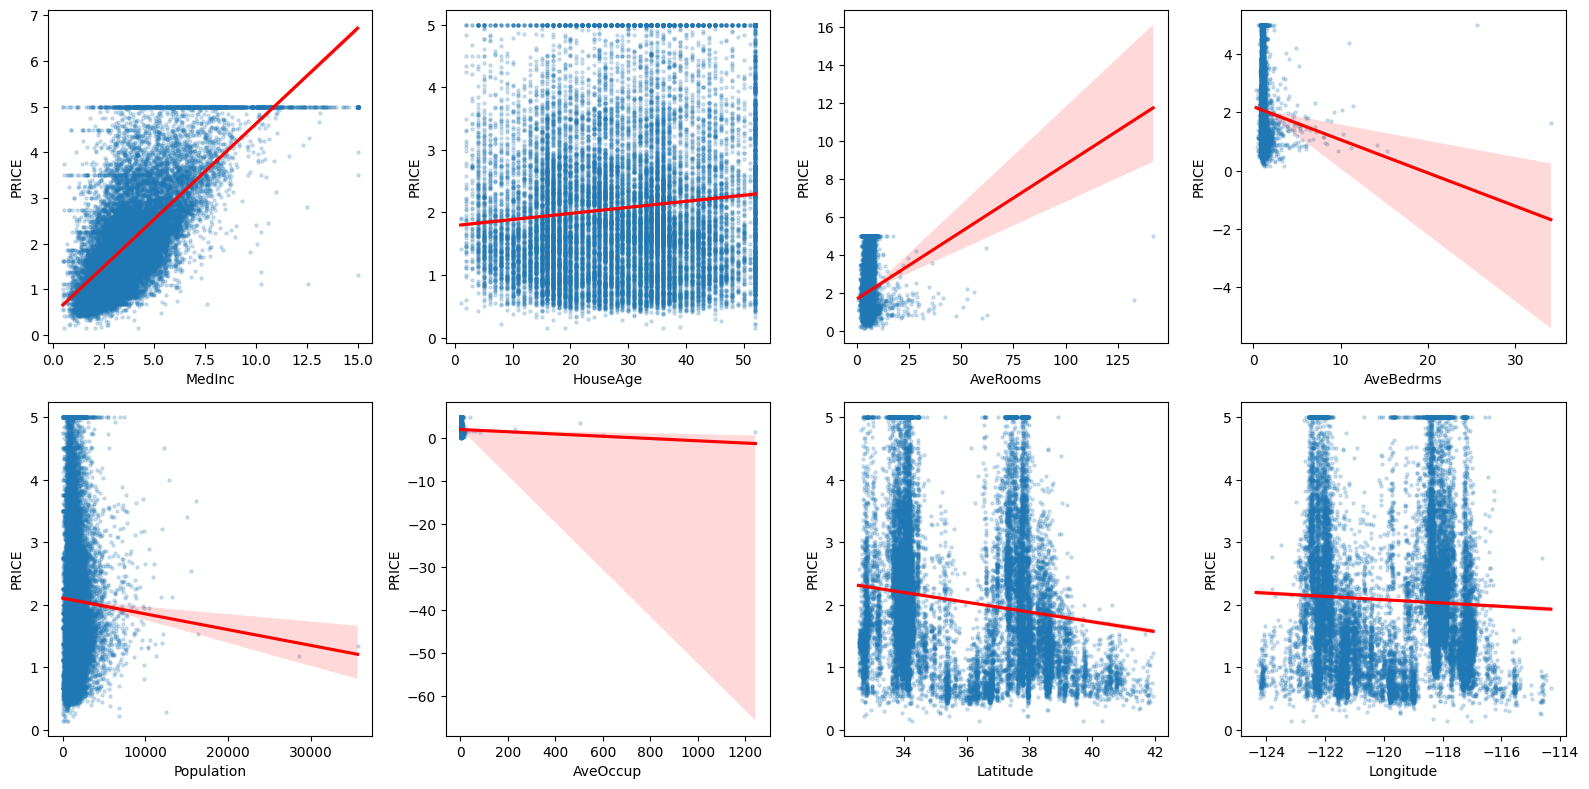

In [5]:
# 4. 각 입력 특성과 주택 가격의 관계를 산점도와 직선으로 살펴봅니다.
# subplots는 한 화면에 여러 그래프 칸(axes)을 만듭니다. 여기서는 2행 × 4열입니다.
# lm_features는 그래프로 확인할 입력 열의 이름 목록입니다.
# enumerate는 순번 i와 특성 이름 feature를 함께 꺼냅니다.
# i를 4로 나눈 몫은 행 번호, 나머지는 열 번호가 되어 8개 그래프를 배치합니다.
# regplot은 점(실제 관측치)과 선형 추세선을 함께 그립니다.
# scatter_kws는 점의 크기/투명도, line_kws는 추세선 색을 정합니다.
# tight_layout은 그래프끼리 제목이나 글자가 겹치지 않도록 여백을 조절합니다.

fig, axs = plt.subplots(figsize = (16,8),ncols = 4 , nrows = 2)
lm_features = [
    "MedInc", "HouseAge", "AveRooms", "AveBedrms",
    "Population", "AveOccup", "Latitude", "Longitude"
]


for i , feature in enumerate(lm_features):
    row =int(i /4)
    col = i %4
    sns.regplot (x = feature , y = "PRICE" , data = df , 
                 ax = axs[row][col],
                 scatter_kws = {"s": 5, "alpha" : 0.2 }, line_kws = {"color":"red"})

plt.tight_layout() ## 얘는 걍 산점도 그래프임

In [6]:
# 5. 데이터를 학습용과 시험용으로 나누고 다중 선형 회귀 모델을 학습합니다.
# X는 입력 특성(문제), y는 정답 PRICE(맞혀야 할 답)입니다.

# 기본적인 선형회귀 / 단항회귀
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

y_target = df["PRICE"]
# drop은 PRICE 열을 제외한 표를 만들며 axis=1은 열을 뜻합니다. 원본 df는 유지합니다.
X_data = df.drop("PRICE", axis=1, inplace=False)


# train_test_split은 데이터를 나눕니다. test_size=0.3은 30%를 시험에 사용합니다.
# random_state를 고정하면 실행할 때마다 같은 방식으로 나뉘어 결과를 비교하기 쉽습니다.
X_train , X_test , y_train , y_test  = train_test_split(X_data, y_target, 
                                                        test_size= 0.3, random_state= 42)

# LinearRegression은 입력값들의 가중합으로 정답을 예측하는 선형 회귀 알고리즘입니다.
lr = LinearRegression()

# fit은 학습, predict는 학습한 규칙으로 시험 입력을 예측하는 메서드입니다.
lr.fit(X_train,y_train)
pred= lr.predict(X_test)
print(pred)

# MSE는 오차를 제곱해 평균한 값이고, RMSE는 그 제곱근이라 원래 정답 단위로 해석하기 쉽습니다.
mse = mean_squared_error(y_test, pred)

# r2_score(R²)는 모델이 정답의 변동을 얼마나 설명하는지 나타냅니다. 보통 1에 가까울수록 좋습니다.
# 음수일 수도 있으며, 지표 하나만으로 모델의 모든 성능을 판단하지는 않습니다.
rmse = np. sqrt(mse)

print(mse)
print(rmse)
#분산 점수 (variance score)
print(r2_score(y_test, pred))

[0.72604907 1.76743383 2.71092161 ... 2.07465531 1.57371395 1.82744133]
0.5305677824766752
0.7284008391515452
0.5957702326061665


In [7]:
# 6. 선형 회귀식의 절편과 각 특성의 계수를 확인합니다.
# 단순한 한 변수 식은 y = a*x + b이고, 여러 입력에서는 각 x의 계수 합에 절편을 더합니다.
# intercept_는 절편 b, coef_는 입력 열마다 하나씩 대응하는 계수(기울기)입니다.
# round(..., 3)은 숫자를 소수 셋째 자리까지 반올림해 보기 좋게 출력합니다.

# y = a*x + b
# lr.intercept_ = b
print(lr.intercept_)
# lr.coef_ = a : 회귀계수
print(np.round(lr.coef_,3))

-37.05624133152527
[ 0.446  0.01  -0.122  0.779 -0.    -0.003 -0.419 -0.434]


In [8]:
# 7. 계수를 특성 이름과 연결해 표처럼 정리합니다.
# Series는 이름(index)과 값(data)이 짝을 이루는 1차원 자료입니다.
# 계수의 부호는 다른 조건이 같을 때 예측값이 어느 방향으로 움직이는지를 나타냅니다.
# 계수 크기를 중요도로 바로 비교할 때는 변수 단위와 스케일이 서로 다를 수 있음을 주의하세요.
# sort_values는 계수 값 기준 정렬이며 ascending=False는 큰 값부터(내림차순) 입니다.

coeff = pd.Series(data = np.round(lr.coef_ , 3),index = X_data.columns)

coeff.sort_values(ascending = False)

AveBedrms     0.779
MedInc        0.446
HouseAge      0.010
Population   -0.000
AveOccup     -0.003
AveRooms     -0.122
Latitude     -0.419
Longitude    -0.434
dtype: float64

In [9]:
# 8. 교차 검증으로 여러 데이터 분할에서 선형 회귀를 평가합니다.
# 그래서 원래 MSE로 바꾸려면 부호를 뒤집습니다.

from sklearn.model_selection import cross_val_score

# cross_val_score는 데이터를 cv=5개의 조각으로 나누고, 매번 한 조각을 검증에 사용합니다.
# scoring의 neg_mean_squared_error는 sklearn의 점수 규칙(클수록 좋음)에 맞추려고 음수 MSE를 반환합니다.
neg_mse_scores = cross_val_score(lr, X_data, y_target, scoring = "neg_mean_squared_error",cv=5)


# 여기서는 정렬한 MSE를 rmse_scores라 이름 붙였지만 실제 값은 RMSE가 아니라 MSE입니다.
rmse_scores = np.sort(-1 * neg_mse_scores)
# 평균도 MSE 평균이며, 이름과 달리 제곱근은 취하지 않았다는 점을 기억하세요.
avg_rmse = np . mean(rmse_scores)

print(np.round(neg_mse_scores,2))
print(np.round(rmse_scores,2))
print(np.round(avg_rmse , 3))

[-0.48 -0.62 -0.65 -0.54 -0.49]
[0.48 0.49 0.54 0.62 0.65]
0.558


In [10]:
# 9. 다음 부분은 다항 회귀입니다. 곡선 관계를 입력 특성의 거듭제곱으로 표현합니다.
##데이터가 곡선 모양!

# 다항회귀

In [11]:
# 10. PolynomialFeatures가 입력 열에서 다항식 조합을 만드는 방식을 작은 예로 봅니다.
# 두 단계를 한꺼번에 하는 fit_transform도 사용할 수 있습니다.

from sklearn.preprocessing import PolynomialFeatures
import numpy as np

# arange(4)는 0, 1, 2, 3을 만들고 reshape(2, 2)는 2행 2열 배열로 바꿉니다.
X = np.arange(4).reshape(2,2)
print("일차 단항식 계수 features : ", X)

# degree=2는 2차까지의 항을 만들며, 기본 include_bias=True라 상수 1 열도 포함합니다.
poly = PolynomialFeatures(degree = 2)

# fit은 입력 열 구성을 확인하고 transform은 실제로 새 특성 배열을 만듭니다.
poly.fit(X)
poly_ftr = poly.transform(X)
print("변환된 2차 다항식 계수",poly_ftr)

일차 단항식 계수 features :  [[0 1]
 [2 3]]
변환된 2차 다항식 계수 [[1. 0. 1. 0. 0. 1.]
 [1. 2. 3. 4. 6. 9.]]


In [12]:
# 11. 미리 정해 둔 다항식 규칙으로 y 값을 직접 계산하는 함수입니다.
# 함수는 def로 정의하며, X[:, 0]은 모든 행의 첫 번째 열, X[:, 1]은 두 번째 열입니다.
# **는 거듭제곱입니다. 각 행의 두 입력값으로 y = 1 + 2*x1 + 3*x1² + 4*x2³을 계산합니다.
# print는 각 열을 확인하기 위한 출력이고 return은 계산 결과를 호출한 곳으로 돌려줍니다.
# 여기서는 사람이 입력한 다항식과 PolynomialFeatures 결과를 나중에 비교합니다.

def polynominal_func(X) : # PolynomicFeatures의 구현 (식이 어케 생겼는 지)
    y = 1+2*X[:,0]+3 *X[:,0]**2 + 4 *X[:,1]**3
    print(X[:,0])
    print(X[:,1])
    return y 

X= np.arange(0,4).reshape(2,2)

print("일차 단항식 계수 feature : ",X)
y = polynominal_func(X)
print("삼차 다항식 결정값: ",y)

일차 단항식 계수 feature :  [[0 1]
 [2 3]]
[0 2]
[1 3]
삼차 다항식 결정값:  [  5 125]


In [13]:
# 12. 같은 X에 3차 다항 특성을 생성합니다.
# degree=3은 3차까지의 항을 만든다는 뜻이며, 입력 열이 여러 개면 열 사이 곱도 포함합니다.
# 이 배열의 각 열은 회귀 모델이 사용할 별도의 입력 변수(특성)가 됩니다.

poly_ftr = PolynomialFeatures(degree = 3).fit_transform(X)
print("3차 다항식 계수 feature :",  poly_ftr)

3차 다항식 계수 feature : [[ 1.  0.  1.  0.  0.  1.  0.  0.  0.  1.]
 [ 1.  2.  3.  4.  6.  9.  8. 12. 18. 27.]]


In [14]:
# 13. 변환된 다항 특성으로 선형 회귀를 학습합니다.
# 다항식 회귀는 입력을 다항 특성으로 바꾼 뒤 그 특성에 선형 회귀를 적용하는 방식입니다.
# fit은 poly_ftr와 y 사이의 계수를 학습합니다. coef_에는 각 특성의 계수가 저장됩니다.
# shape는 계수 배열의 길이(특성 수)를 알려줍니다. 상수항은 기본적으로 절편에 반영됩니다.

model = LinearRegression()
model.fit(poly_ftr, y)
print('다항식의 회귀 계수 : ', np.round(model.coef_ , 2))
print("다항식의 회귀 shape : ", model.coef_.shape)

다항식의 회귀 계수 :  [0.   0.18 0.18 0.36 0.54 0.72 0.72 1.08 1.62 2.34]
다항식의 회귀 shape :  (10,)


In [15]:
# 14. 특성 변환과 회귀를 Pipeline으로 묶어 한 모델처럼 사용합니다.
# Pipeline은 순서대로 변환과 학습을 연결해, 예측/교차검증 때 같은 변환이 자동 적용되게 합니다.
# 첫 단계 poly는 3차 특성 생성, 둘째 linear는 선형 회귀입니다.
# named_steps로 파이프라인 안의 이름을 지정해 해당 단계에 접근할 수 있습니다.
# 이 예시는 설명용으로 표본이 두 개뿐이라 실제 일반화 성능을 평가하기 위한 데이터는 아닙니다.

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
import numpy as np

def polynominal_func(X) : 
    y = 1    +2*X[:,0]  +3*X[:,0]**2  +4 *X[:,1]**3
    return y

model = Pipeline([
    ("poly", PolynomialFeatures(degree=3)),
    ("linear", LinearRegression())
])

X = np.arange(4).reshape(2,2)
y = polynominal_func(X)

model.fit(X, y)
print(np.round(model.named_steps["linear"].coef_, 2))

[0.   0.18 0.18 0.36 0.54 0.72 0.72 1.08 1.62 2.34]


In [16]:
# 15. 과소적합과 과대적합을 보여 줄 간단한 곡선 데이터를 만듭니다.
# true_fun은 우리가 알고 있는 실제 규칙(코사인 곡선)입니다.
# random.seed를 고정해 난수가 매번 같은 값으로 나오게 합니다.
# rand는 0 이상 1 미만의 무작위 수를 만들고 sort는 x를 오름차순으로 정렬합니다.
# y에는 실제 곡선값에 평균 0인 작은 잡음을 더해 현실의 측정 오차처럼 만듭니다.

import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

def true_fun(X):
    return np.cos(1.5 * np.pi * X)

np.random.seed(0)
n_sample = 30
X = np.sort(np.random.rand(n_sample))

y = true_fun(X) + np.random.randn(n_sample)*0.1


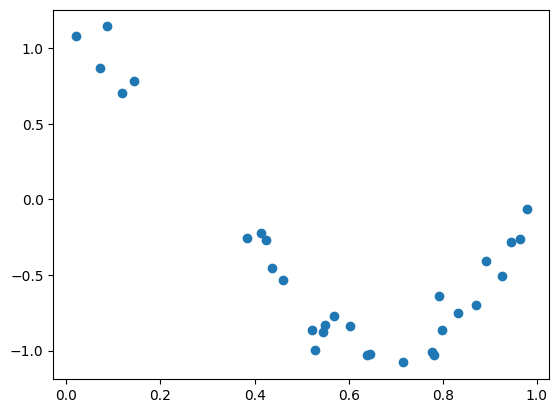

In [17]:
# 16. 생성한 표본 x와 y를 점으로 그려 데이터 분포를 확인합니다.
# scatter는 산점도입니다. 아직 모델 선은 그리지 않았습니다.

plt.scatter(X,y)

1 [-1.61]
1 0.40772896250986845
4 [  0.47 -17.79  23.59  -7.26]
4 0.04320874987231814
15 [-2.98292000e+03  1.03899210e+05 -1.87415866e+06  2.03716020e+07
 -1.44873197e+08  7.09315193e+08 -2.47065814e+09  6.24561298e+09
 -1.15676589e+10  1.56895083e+10 -1.54006206e+10  1.06457414e+10
 -4.91378328e+09  1.35919894e+09 -1.70381130e+08]
15 181082440.22779876


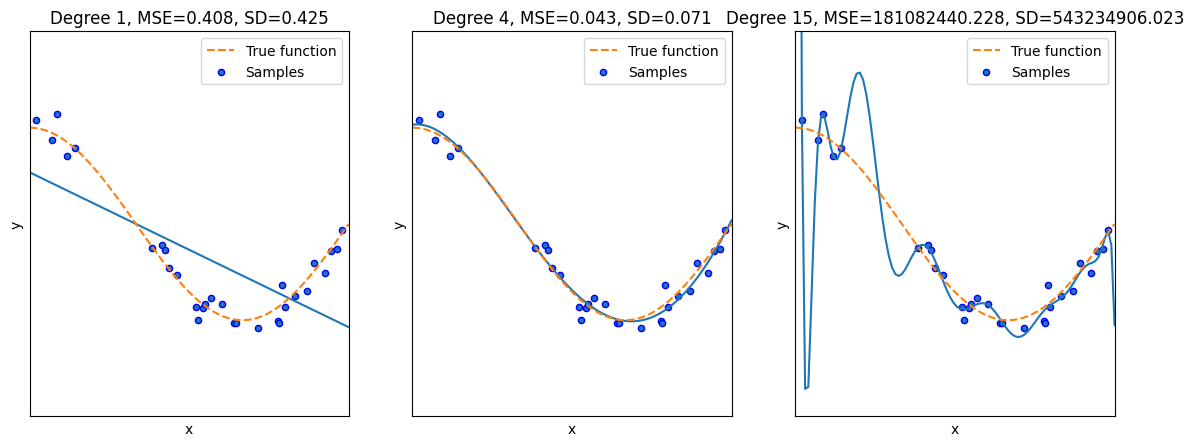

In [18]:
# 17. 차수가 다른 세 모델을 비교해 과소적합과 과대적합을 관찰합니다.
# reshape(-1, 1)은 1차원 x를 sklearn이 요구하는 (표본 수, 특성 수) 모양으로 바꿉니다.
# Pipeline 안에서 다항 변환 후 선형 회귀를 학습하며, 교차 검증으로 검증 오차도 계산합니다.
# 계수는 각 다항 특성의 가중치입니다. 차수가 커지면 계수와 곡선이 복잡해질 수 있습니다.
# linspace는 0~1 구간의 촘촘한 x값을 만들어 부드러운 예측선을 그립니다.
# 실선은 모델 예측, 점선은 실제 규칙, 점은 관측 표본입니다.
# 차수 1은 곡선 패턴을 놓쳐 과소적합할 수 있고, 차수 15는 잡음까지 따라가 과대적합할 수 있습니다.
# 제목의 MSE는 교차 검증 오차 평균, SD는 점수의 표준편차(분할별 변동)입니다.

plt. figure ( figsize = (14,5))
# degrees=[1, 4, 15]는 각각 직선, 적당히 굽은 곡선, 매우 복잡한 곡선을 뜻합니다.
degrees = [1,4,15]


# 반복문은 각 차수별로 같은 과정을 수행하고, subplot은 나란한 그래프 칸을 만듭니다.
for i  in range(len(degrees)):
    ax = plt.subplot(1, len(degrees), i + 1)
    plt.setp(ax, xticks = (), yticks= ())

# include_bias=False는 상수 1 특성을 만들지 않게 합니다(회귀 절편이 별도로 있기 때문).
    polynominal_features = PolynomialFeatures(degree= degrees[i], include_bias= False)

    linear_regression = LinearRegression()
    Pipline = Pipeline([("polynimail_features",polynominal_features),("linear_regression",linear_regression)])
    Pipline.fit(X.reshape(-1, 1), y)

    scores = cross_val_score(Pipline, X.reshape(-1, 1),y,scoring = "neg_mean_squared_error", cv = 10)

    coefficients = Pipline.named_steps["linear_regression"].coef_
    print(degrees[i],np.round(coefficients,2))
    print(degrees[i], -1 * np.mean(scores))

    X_test = np.linspace(0, 1, 100)
    plt.plot(X_test, Pipline.predict(X_test[:,np.newaxis]))
    plt.plot(X_test, true_fun(X_test), "--",label = "True function")
    plt.scatter(X,y, edgecolors= "b",s = 20, label = "Samples")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.xlim((0,1))
    plt.ylim((-2,2))
    plt.legend(loc="best")
    plt.title(
    f"Degree {degrees[i]}, MSE={-scores.mean():.3f}, SD={scores.std():.3f}") 
plt.show()

In [19]:
# 18. Ridge 회귀를 5겹 교차 검증으로 평가합니다.
# Ridge는 계수 크기에 벌점을 더해 지나치게 큰 계수를 억제하는 선형 회귀입니다.
# alpha는 벌점의 세기입니다. 값이 커질수록 계수를 더 강하게 줄입니다.
# alpha=10 모델을 검증하고, 음수 MSE를 양수로 바꾼 뒤 제곱근을 취해 각 RMSE를 구합니다.
# 다섯 검증 조각의 RMSE 평균을 출력합니다.

from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing()
df = pd.DataFrame(housing.data , columns= housing.feature_names)

df [ "PRICE"] = housing.target

y_target = df [ "PRICE"]
X_data = df.drop(["PRICE"], axis = 1, inplace = False)

ridge = Ridge(alpha = 10)

neg_mse_scores = cross_val_score(ridge , X_data, y_target, scoring= "neg_mean_squared_error", cv =5)
rmse_scores = np.sqrt(-1*neg_mse_scores)
avg_rmse = np.mean(rmse_scores)

print( np. round(neg_mse_scores , 3))
print( np. round(rmse_scores , 3))
print( np. round(avg_rmse , 3))

[-0.484 -0.623 -0.646 -0.544 -0.494]
[0.695 0.789 0.804 0.737 0.703]
0.746


In [20]:
# 19. 여러 alpha 후보 중 교차 검증 오차가 어떻게 달라지는지 비교합니다.

# alpha=0은 사실상 벌점이 없는 선형 회귀에 해당합니다.
alphas = [0,0.1,1,10,100]

# 반복할 때마다 새 Ridge 모델을 만들고 5겹 교차 검증 점수를 계산합니다.
for alpha in alphas:
    ridge = Ridge(alpha=alpha)

    # neg_mse_scores는 음수 MSE이므로 부호를 뒤집어 양수로 바꾸고 평균을 냅니다.
    neg_mse_scores = cross_val_score(ridge, X_data, y_target,
                                     scoring= 'neg_mean_squared_error',cv = 5)
    avg_rmse = np.mean(np.sort(-1*neg_mse_scores))
    print(alpha, avg_rmse)

# 이 셀은 평균 MSE를 출력합니다. 변수명 avg_rmse와 달리 제곱근은 아직 계산하지 않았습니다.


0 0.5582901717686554
0.1 0.5582890168261192
1 0.5582787258685613
10 0.5581857057691506
100 0.5579724434119424


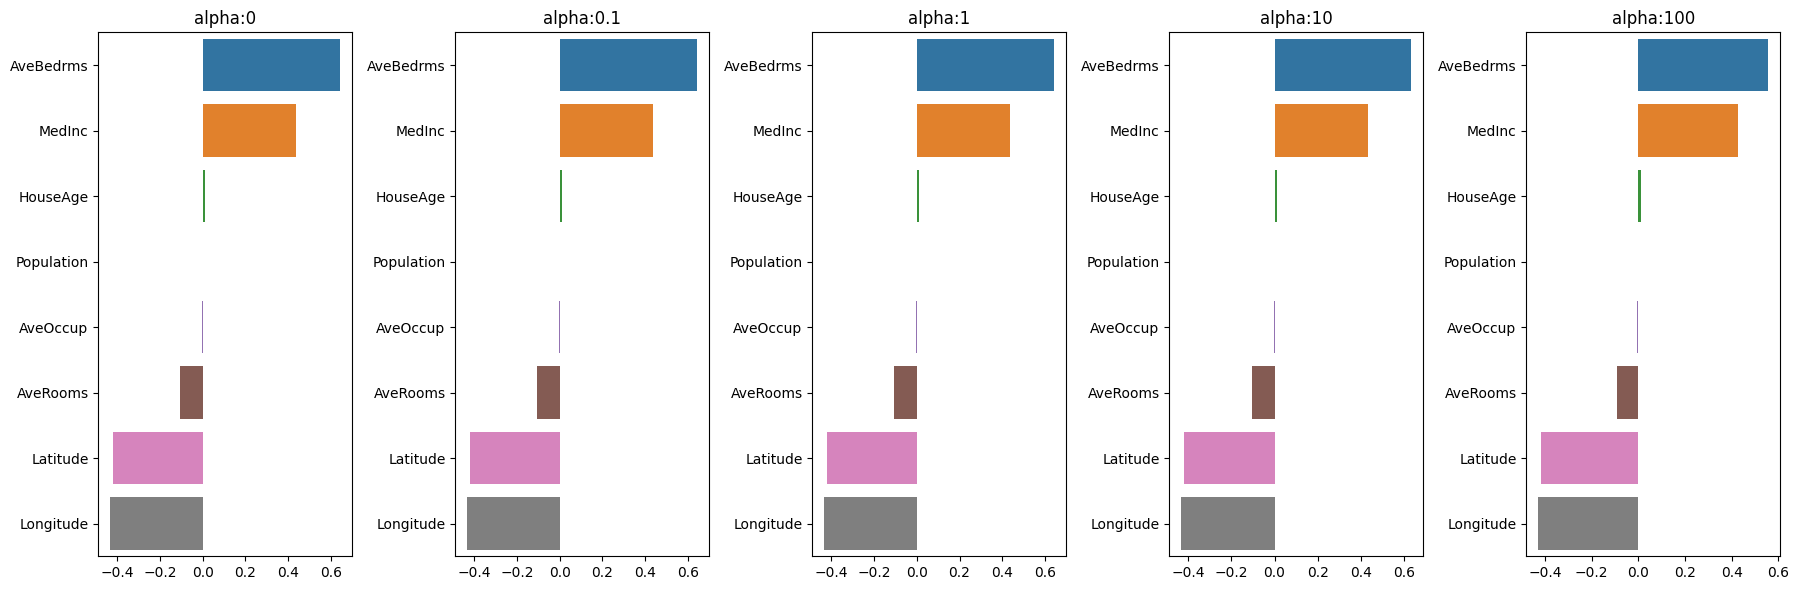

In [21]:
# 20. alpha별 Ridge 계수를 학습해 표와 막대그래프로 비교합니다.

fig,axs = plt.subplots(figsize= (18,6),nrows = 1 , ncols = 5) 
coeff_df = pd.DataFrame()


# enumerate는 그래프 위치 pos와 alpha 값을 함께 제공합니다.
for pos, alpha in enumerate(alphas) : 
    ridge = Ridge(alpha=alpha)
    
    # fit은 전체 데이터를 사용해 계수를 구합니다(앞 셀의 교차 검증과 목적이 다릅니다).
    ridge . fit (X_data, y_target)

    # Series에 특성 이름을 붙인 뒤 coeff_df의 해당 alpha 열로 저장합니다.
    coeff = pd.Series(data = ridge.coef_,index = X_data.columns)
    colname ="alpha:" + str(alpha)

    # coeff_df는 alpha마다 계수 한 열을 보관할 빈 DataFrame입니다.  
    coeff_df[colname] = coeff
    coeff = coeff.sort_values(ascending=False)
    axs[pos].set_title(colname)  
    
    # 정렬된 계수를 seaborn 막대그래프로 표시합니다. 계수가 양수/음수인지와 크기를 함께 봅니다.
    sns.barplot(x=coeff.values, y=coeff.index, ax=axs[pos])


# tight_layout은 배치를 정돈하고 show는 그래프를 화면에 표시합니다.
plt.tight_layout()
plt.show()

In [22]:
# 21. 앞 셀에서 만든 계수 표를 지정한 alpha 열 기준으로 정렬해 봅니다.
# sort_values의 by는 정렬에 쓸 열 이름입니다. 현재 ridge_alphas[0]은 0이라 'alpha:0' 열입니다.
# 계수는 음수도 있으므로 내림차순은 큰 양수부터 표시합니다.

ridge_alphas = [0,0.1,1,10,100]
sort_column = "alpha:" + str(ridge_alphas[0])
coeff_df.sort_values(by=sort_column, ascending=False) 

,alpha:0,alpha:0.1,alpha:1,alpha:10,alpha:100
AveBedrms,0.645066,0.644965,0.644062,0.635174,0.558249
MedInc,0.436693,0.436683,0.436594,0.435719,0.428210
HouseAge,0.009436,0.009436,0.009437,0.009452,0.009592
Population,-0.000004,-0.000004,-0.000004,-0.000004,-0.000003
AveOccup,-0.003787,-0.003787,-0.003786,-0.003785,-0.003773
AveRooms,-0.107322,-0.107303,-0.107133,-0.105456,-0.091012
Latitude,-0.421314,-0.421313,-0.421299,-0.421156,-0.419061
Longitude,-0.434514,-0.434511,-0.434485,-0.434217,-0.430993


In [23]:
# 22. Ridge, Lasso, ElasticNet을 같은 방식으로 평가하는 재사용 함수입니다.
# cross_val_score의 기본 cv 설정으로 점수를 얻습니다. scoring을 지정하지 않아 회귀의 기본 R² 점수입니다.
# 따라서 아래에서 -1을 곱해 제곱근을 취하는 계산은 올바른 RMSE가 아닙니다. <--?예?
# RMSE를 의도했다면 scoring='neg_mean_squared_error'를 명시해야 합니다.
# 모델은 교차 검증 평가 뒤 전체 데이터로 다시 학습하고, coef_를 특성 이름과 함께 저장합니다.

# Lasso는 절댓값 계수 합(L1) 벌점으로 일부 계수를 정확히 0으로 만들 수 있습니다.
from sklearn.linear_model import Lasso, ElasticNet

# 매개변수는 함수에 전달할 입력입니다. 기본값 None은 값이 생략됐음을 뜻합니다.
def get_linear_reg_eval (model_name, params = None, X_data_n = None, y_target_n=None , verdose = True, return_coeff = True):
    
    coeff_df = pd.DataFrame()
    # verdose는 출력 여부를 제어하는 스위치(이름은 verbose의 오타), return_coeff는 계수 반환 여부입니다.
    if verdose : print("#####" , model_name, "#####")
    # 각 param(alpha 후보)에 따라 모델 종류를 선택합니다.
    for param in params :
        if model_name == "Ridge" : model = Ridge(alpha= param)
        elif model_name == "Lasso" : model = Lasso(alpha= param)
        elif model_name == "ElasticNet" :
        # ElasticNet은 L1과 제곱 계수(L2) 벌점을 섞으며 l1_ratio가 섞는 비율을 정합니다.
            model = ElasticNet(alpha= param , l1_ratio= 0.7)
        neg_mse_scores = cross_val_score(model, X_data_n,y_target_n)
        avg_rmse = np.mean(np.sqrt(-1 * neg_mse_scores))
        print(param, avg_rmse)


        model.fit(X_data_n, y_target_n)
        if return_coeff : 
            coeff = pd.Series(data = model.coef_,
            index = X_data_n.columns)

            colname = "alpha"+str(param)
            coeff_df[colname] = coeff

    # 반환값 coeff_df에는 alpha별 계수 열이 들어갑니다.
    return coeff_df

In [24]:
# 23. Lasso의 alpha 후보들을 위 함수에 전달해 성능과 계수를 계산합니다.
# 결과 DataFrame에는 alpha0.07, alpha0.1처럼 각 벌점 강도의 계수 열이 생깁니다.
# 이 함수 호출에서도 scoring 기본값이 R²이므로 출력된 값은 RMSE가 아니라는 점에 주의하세요.

lasso_alpha = [0.07 , 0.1, 0.5, 1, 3]
coeff_lasso_df = get_linear_reg_eval("Lasso",
                                     params= lasso_alpha , X_data_n= X_data,
                                     y_target_n= y_target)

##### Lasso #####
0.07 nan
0.1 nan
0.5 nan
1 nan
3 0.2826584655136458


In [25]:
# 24. 가장 작은 Lasso alpha에 해당하는 계수 열을 기준으로 정렬합니다.

# 열 이름은 함수에서 'alpha' + 숫자로 만들어져 alpha0.07 형식입니다.
# 이 결과를 통해 벌점이 약할 때 어떤 입력 특성의 계수가 큰지 살펴볼 수 있습니다.

sort_column = "alpha" + str(lasso_alpha[0])
coeff_lasso_df.sort_values(by=sort_column, ascending=False)

,alpha0.07,alpha0.1,alpha0.5,alpha1,alpha3
MedInc,0.387057,0.390583,0.288855,0.145469,0.000000
HouseAge,0.013391,0.015082,0.012031,0.005815,0.000000
Population,0.000010,0.000018,0.000012,-0.000006,-0.000023
AveRooms,-0.000000,-0.000000,0.000000,0.000000,0.000000
AveBedrms,0.000000,0.000000,-0.000000,-0.000000,-0.000000
AveOccup,-0.003409,-0.003323,-0.000000,-0.000000,-0.000000
Longitude,-0.204689,-0.099225,-0.000000,-0.000000,-0.000000
Latitude,-0.212806,-0.114214,-0.000000,-0.000000,-0.000000


In [26]:
# 25. alpha3 열을 기준으로 계수를 내림차순 정렬합니다.

# alpha가 큰 모델은 계수를 더 강하게 줄이며, Lasso에서는 여러 계수가 0이 될 수 있습니다.
# sort_columns 변수는 만들어지지만 아래 정렬에서는 사용하지 않는다는 점도 확인해 보세요.

sort_columns = "alpha:" + str(lasso_alpha)
coeff_lasso_df.sort_values(by="alpha3", ascending=False)

,alpha0.07,alpha0.1,alpha0.5,alpha1,alpha3
MedInc,0.387057,0.390583,0.288855,0.145469,0.000000
HouseAge,0.013391,0.015082,0.012031,0.005815,0.000000
AveRooms,-0.000000,-0.000000,0.000000,0.000000,0.000000
AveBedrms,0.000000,0.000000,-0.000000,-0.000000,-0.000000
AveOccup,-0.003409,-0.003323,-0.000000,-0.000000,-0.000000
Latitude,-0.212806,-0.114214,-0.000000,-0.000000,-0.000000
Longitude,-0.204689,-0.099225,-0.000000,-0.000000,-0.000000
Population,0.000010,0.000018,0.000012,-0.000006,-0.000023


In [ ]:
# 26. ElasticNet도 alpha별로 평가하고 계수를 표로 정리하려는 셀입니다.

# 마지막 정렬은 alpha3 계수를 내림차순으로 보여 줍니다.

elastic_alpha = [0.07 , 0.1, 0.5, 1, 3]
coeff_elastic_df = get_linear_reg_eval("ElasticNet",
                                     params= elastic_alpha , X_data_n= X_data,
                                     y_target_n= y_target)

sort_columns = "elastic:" + str(coeff_elastic_df)
coeff_elastic_df.sort_values(by="alpha3", ascending=False)

##### ElasticNet #####
0.07 nan
0.1 nan
0.5 nan
1 nan
3 0.2825881033610346


,alpha0.07,alpha0.1,alpha0.5,alpha1,alpha3
MedInc,0.384500,0.385980,0.318532,0.213455,0.000000
HouseAge,0.012534,0.013697,0.013662,0.009156,0.000000
AveRooms,0.000000,-0.000000,0.000000,0.000000,0.000000
AveBedrms,0.000000,0.000000,-0.000000,-0.000000,-0.000000
AveOccup,-0.003502,-0.003437,-0.000837,-0.000000,-0.000000
Latitude,-0.264115,-0.195109,-0.000000,-0.000000,-0.000000
Longitude,-0.259559,-0.185737,-0.000000,-0.000000,-0.000000
Population,0.000007,0.000012,0.000018,0.000003,-0.000023
